<a href="https://colab.research.google.com/github/shaikimran2101227-del/Monte-Carlo-Portfolio-Risk-Simulator/blob/main/Monte_Carlo_Portfolio_Risk_Simulator_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Set Seed and Asset Parameters

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

mean_returns = np.array([0.0004, 0.0006, 0.0003, 0.0005])
volatility = np.array([0.01, 0.015, 0.012, 0.02])
weights = np.array([0.25, 0.25, 0.25, 0.25])

initial_value = 100000
days = 252
simulations = 10000

print("Asset Mean Returns:", mean_returns)
print("Asset Volatility:", volatility)
print("Portfolio Weights:", weights)

Asset Mean Returns: [0.0004 0.0006 0.0003 0.0005]
Asset Volatility: [0.01  0.015 0.012 0.02 ]
Portfolio Weights: [0.25 0.25 0.25 0.25]


Simulate 10,000 × 252 × 4 Returns

In [2]:
returns = np.random.normal(
    mean_returns,
    volatility,
    (simulations, days, 4)
)

print("Returns Shape:", returns.shape)
print("Number of Simulations:", simulations)
print("Trading Days:", days)
print("Number of Assets:", returns.shape[2])

Returns Shape: (10000, 252, 4)
Number of Simulations: 10000
Trading Days: 252
Number of Assets: 4


Calculate Portfolio Paths

In [3]:
daily_portfolio_returns = returns @ weights

log_returns = np.log1p(daily_portfolio_returns)

cumulative_returns = np.exp(np.cumsum(log_returns, axis=1))

portfolio_paths = initial_value * cumulative_returns

final_values = portfolio_paths[:, -1]

print("Portfolio Paths Shape:", portfolio_paths.shape)
print("First 10 Final Values:")
print(final_values[:10])

Portfolio Paths Shape: (10000, 252)
First 10 Final Values:
[123285.05946436 137550.79987042 114240.39079046 103159.72672418
  97203.83722628  92245.83763656 100360.7965849  116691.74408993
 124218.63465521 109861.85385198]


Calculate Volatility and 95% VaR

In [4]:
portfolio_returns = (final_values - initial_value) / initial_value

portfolio_volatility = np.std(portfolio_returns)

losses = initial_value - final_values

var_95 = np.percentile(losses, 95)

print("Initial Portfolio Value:", initial_value)
print("Average Final Value:", np.mean(final_values))
print("Minimum Final Value:", np.min(final_values))
print("Maximum Final Value:", np.max(final_values))
print("Annual Volatility:", portfolio_volatility * 100, "%")
print("95% Value-at-Risk:", var_95)

Initial Portfolio Value: 100000
Average Final Value: 111988.39780143995
Minimum Final Value: 68643.95539832539
Maximum Final Value: 189936.1520296212
Annual Volatility: 13.073650176112292 %
95% Value-at-Risk: 7773.749604256151


Portfolio Value Histogram

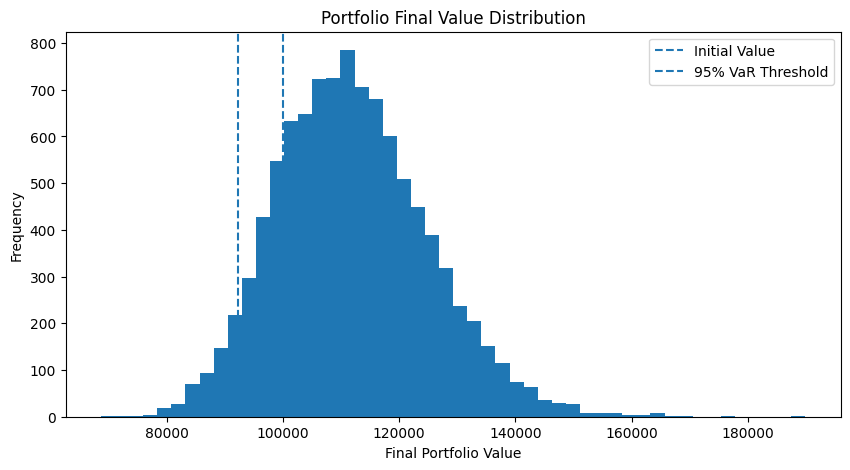

In [5]:
plt.figure(figsize=(10, 5))

plt.hist(final_values, bins=50)

plt.axvline(initial_value, linestyle="--", label="Initial Value")
plt.axvline(initial_value - var_95, linestyle="--", label="95% VaR Threshold")

plt.title("Portfolio Final Value Distribution")
plt.xlabel("Final Portfolio Value")
plt.ylabel("Frequency")
plt.legend()
plt.show()

Sample Portfolio Paths

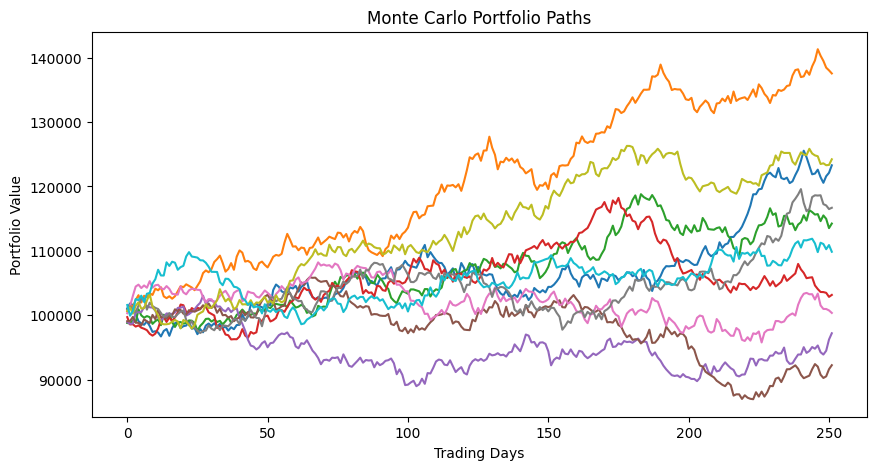

In [6]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.plot(portfolio_paths[i])

plt.title("Monte Carlo Portfolio Paths")
plt.xlabel("Trading Days")
plt.ylabel("Portfolio Value")
plt.show()

Portfolio Summary

In [7]:
profitable = np.sum(final_values > initial_value)
loss_count = np.sum(final_values < initial_value)

print("Total Simulations:", simulations)
print("Profitable Simulations:", profitable)
print("Loss-Making Simulations:", loss_count)
print("Probability of Profit:", profitable / simulations * 100, "%")
print("Probability of Loss:", loss_count / simulations * 100, "%")

Total Simulations: 10000
Profitable Simulations: 8181
Loss-Making Simulations: 1819
Probability of Profit: 81.81 %
Probability of Loss: 18.19 %


Market Crash Stress Test

In [8]:
shock_values = [0, -0.05, -0.10]
scenario_names = ["Normal Market", "Moderate Crash", "Severe Crash"]

scenario_values = []
scenario_vars = []
scenario_losses = []

for shock in shock_values:
    new_returns = returns.copy()
    new_returns[:, 125, :] = new_returns[:, 125, :] + shock

    new_portfolio_returns = new_returns @ weights
    new_log_returns = np.log1p(new_portfolio_returns)
    new_paths = initial_value * np.exp(np.cumsum(new_log_returns, axis=1))
    new_final_values = new_paths[:, -1]

    losses = initial_value - new_final_values

    scenario_values.append(np.mean(new_final_values))
    scenario_vars.append(np.percentile(losses, 95))
    scenario_losses.append(np.mean(new_final_values < initial_value))

for i in range(3):
    print(scenario_names[i])
    print("Average Final Value:", scenario_values[i])
    print("95% VaR:", scenario_vars[i])
    print("Probability of Loss:", scenario_losses[i] * 100, "%")

Normal Market
Average Final Value: 111988.39780143995
95% VaR: 7773.749604256151
Probability of Loss: 18.19 %
Moderate Crash
Average Final Value: 106391.15126935915
95% VaR: 12387.676690840275
Probability of Loss: 31.990000000000002 %
Severe Crash
Average Final Value: 100793.90473727834
95% VaR: 16988.328978066613
Probability of Loss: 49.91 %


Portfolio Allocation Graph

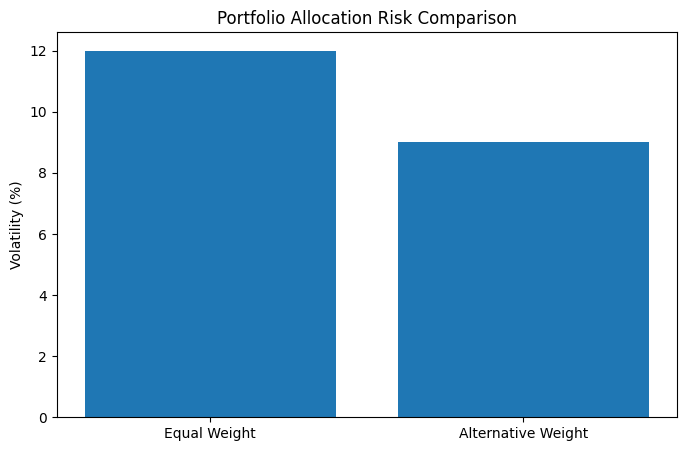

In [13]:

import matplotlib.pyplot as plt

# Example portfolio risk values
risk1 = 0.12
risk2 = 0.09

plt.figure(figsize=(8, 5))

plt.bar(
    ["Equal Weight", "Alternative Weight"],
    [risk1 * 100, risk2 * 100]
)

plt.title("Portfolio Allocation Risk Comparison")
plt.ylabel("Volatility (%)")
plt.show()
